# 01 - poking at the environment

Quick sanity checks and one episode with the heuristics, mostly to see whether the dynamics look
reasonable before training anything.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from agents import BASELINES
from evals.metrics import compute_metrics
from evals.runner import run_episode
from evals.scenarios import make_env

env = make_env("normal")
obs, info = env.reset(seed=0)
print(info)
print("obs:", env.observation_space.shape, "  action:", env.action_space)

{'scenario': 'normal', 'episode_seed': 5874934615388537134}
obs: (94,)   action: MultiDiscrete([5 5 5 5 5 5 5 5 5 2 3 3 3 7 7 7 2 2 3])


In [2]:
o = env.decode_obs(obs)
pd.DataFrame(o["on_hand"], index=env.params.wh_names, columns=env.params.prod_names).round(1)

,fresh_milk,cereal,blender
North,160.0,100.0,16.0
Central,200.0,120.0,24.0
South,120.0,80.0,12.0


Starting stock is 4 days of local demand. What does one random action look like?

In [3]:
a = env.action_space.sample()
print(env.action_layout.decode(a))
obs, r, term, trunc, info = env.step(a)
print(f"reward {r:.2f} (in $1000)")
pd.Series(info["money"]).round(1)

Action(order_lots=array([[4, 1, 1],
       [0, 0, 4],
       [2, 0, 3]]), expedite=False, production=array([1, 2, 1]), transfers=array([3, 0, 2]), allocation=1, sourcing=0, carrier=1)
reward 1.46 (in $1000)


revenue            5336.0
cogs               2996.0
waste_value           0.0
disposal              0.0
procurement        2015.0
shift               520.0
inbound_freight      51.5
transfer             36.6
truck               217.3
express               0.0
handling             20.2
holding              36.2
overflow              0.0
late_penalty          0.0
lost_penalty          0.0
termination           0.0
dtype: float64

## One episode of the warehouse failure scenario

Central is closed on days 18-30. Comparing the static (s, S) rule with the forecast heuristic.

In [4]:
env = make_env("warehouse_failure")
tr = {name: run_episode(env, BASELINES[name](), seed=1) for name in ["rule_based", "forecast"]}
pd.DataFrame(tr["forecast"].events_log, columns=["day", "event"])

,day,event
0,0,supplier shipments delayed 3d
1,4,demand spike x1.7 in region North
2,8,demand spike x2.4 in region North
3,16,damaged delivery at North (15%)
4,18,[scheduled d18-30] Central warehouse down
5,24,demand spike x1.5 in region South
6,27,damaged delivery at Central (26%)
7,33,supplier shipments delayed 2d
8,34,damaged delivery at Central (24%)
9,35,supplier shipments delayed 3d


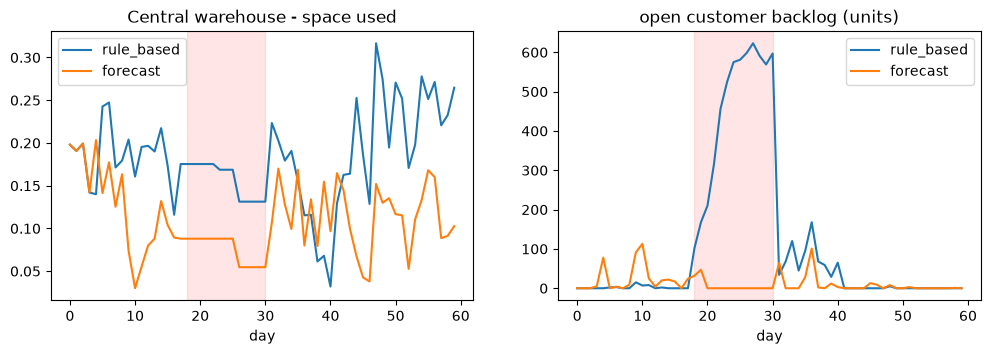

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for name, t in tr.items():
    d = t.daily_frame()
    axes[0].plot(d.day, d["utilization|Central"], label=name)
    axes[1].plot(d.day, d.filter(like="backlog|").sum(axis=1), label=name)
axes[0].set_title("Central warehouse - space used")
axes[1].set_title("open customer backlog (units)")
for ax in axes:
    ax.axvspan(18, 30, color="red", alpha=0.1)
    ax.set_xlabel("day")
    ax.legend()
plt.show()

rule_based only ships from the home warehouse, so Central's customers just wait while it's closed (and
cancel after a few days). The forecast heuristic switches to flexible sourcing when a warehouse is down and
plans Central's demand at the nearest open warehouse.

In [6]:
rows = ["score", "net_profit", "service_penalty", "fill_rate", "otif_rate", "shipping_cost", "lost_units"]
pd.DataFrame({name: compute_metrics(t) for name, t in tr.items()}).loc[rows]

,rule_based,forecast
score,57682.6655,70328.366
net_profit,67341.5655,70705.766
service_penalty,9658.9,377.4
fill_rate,0.9563,1.0
otif_rate,0.914074,0.994734
shipping_cost,13934.86,18351.305
lost_units,583.0,0.0


## Does the money add up?

The sum of rewards should be exactly profit minus penalties (proper test in `tests/test_accounting.py`).

In [7]:
t = tr["forecast"]
m = compute_metrics(t)
print(sum(d["reward"] for d in t.days), m["net_profit"] - m["service_penalty"])

70328.366 70328.36600000001


## Demand vs. forecast (fresh milk, all regions)

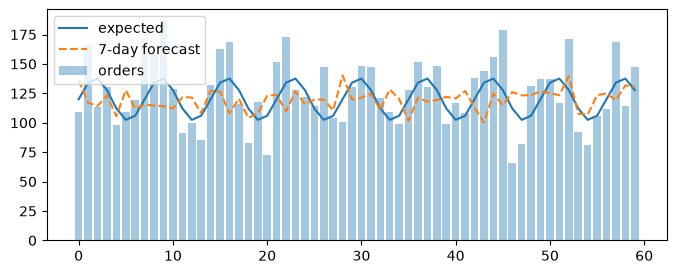

In [8]:
d = tr["forecast"].daily_frame()
plt.figure(figsize=(8, 3))
plt.bar(d.day, d.filter(regex=r"^demand\|.*fresh_milk").sum(axis=1), alpha=0.4, label="orders")
plt.plot(d.day, d.filter(regex=r"^expected_demand\|.*fresh_milk").sum(axis=1), label="expected")
plt.plot(d.day, d.filter(regex=r"^forecast\|.*fresh_milk").sum(axis=1), "--", label="7-day forecast")
plt.legend()
plt.show()

The forecast is smoother than the orders (it averages the next 7 days) and doesn't know about the random
demand spikes, those only show up in `recent_demand` after they happen.